# Step 3: label GPS points

Align each training trip's GPS points to its supplied reference route, in route order. Repeated arcs keep separate route positions.

We cap alignment costs at **150 m**, choose the flag threshold from the **99th percentile of aligned distances across training points**, and keep flagged rows with `true_arc_id = -1`. Labels come from this reference-route alignment; they are not independent pointwise ground truth.

Run from top to bottom. Only training trips are used.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import LineString
from pyproj import Transformer
import matplotlib.pyplot as plt
import folium
from branca.colormap import linear

train = Path("Student folder/train")
label_folder = Path("outputs/labels")
label_folder.mkdir(parents=True, exist_ok=True)
cap_m = 150
flag_percentile = 99

## 1. Load and project a trip

Use the same file loading and per-trip UTM projection as notebook 02. Add the reference route. Arc IDs are row numbers in `.arcs`; route positions are row numbers in `.route`.

In [2]:
def load_trip(trip_id):
    folder = train / trip_id
    nodes = pd.read_csv(folder / f"{trip_id}.nodes", sep=r"\s+", header=None, names=["lon", "lat"])
    arcs = pd.read_csv(folder / f"{trip_id}.arcs", sep=r"\s+", header=None, names=["start", "end"])
    track = pd.read_csv(folder / f"{trip_id}.track", sep=r"\s+", header=None, names=["lon", "lat", "time"])
    route = pd.read_csv(folder / f"{trip_id}.route", sep=r"\s+", header=None, names=["arc_id"])

    zone = int((track["lon"].mean() + 180) // 6) + 1
    epsg = (32600 if track["lat"].mean() >= 0 else 32700) + zone
    projection = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True)
    nodes["x"], nodes["y"] = projection.transform(nodes["lon"], nodes["lat"])
    track["x"], track["y"] = projection.transform(track["lon"], track["lat"])
    return nodes, arcs, track, route

## 2. Align in route order

`D[i, j]` is the distance from GPS point `i` to route position `j`.

For each point, find the cheapest earlier alignment ending at position `j` or before it. `minimum.accumulate` computes those prefix minima in one pass. Store the earliest position attaining each minimum, then backtrack from the cheapest final position.

Staying on a segment and skipping segments are allowed. This does not force every route segment to receive a point. Capping costs limits the influence of distant points, but does not guarantee that bad points have no effect. Store only one row of DP costs plus the backtracking positions.

In [3]:
def align_points(D, cap_m):
    n, r = D.shape
    parents = np.zeros((n, r), dtype=np.int32)
    previous = np.minimum(D[0], cap_m)

    for i in range(1, n):
        prefix = np.minimum.accumulate(previous)
        improved = np.r_[True, previous[1:] < prefix[:-1]]
        parents[i] = np.maximum.accumulate(np.where(improved, np.arange(r), 0))
        previous = np.minimum(D[i], cap_m) + prefix

    route_pos = np.zeros(n, dtype=np.int32)
    route_pos[-1] = previous.argmin()
    for i in range(n - 1, 0, -1):
        route_pos[i - 1] = parents[i, route_pos[i]]
    return route_pos

## 3. Label all training trips

Build the full GPS-to-route distance matrix one trip at a time. No spatial index is needed. Use route positions for alignment, then look up the corresponding arc IDs. Keep the uncapped distances for flagging.

In [4]:
all_labels = {}
route_sizes = {}

for folder in sorted(train.iterdir()):
    if not folder.is_dir():
        continue
    trip_id = folder.name
    nodes, arcs, track, route = load_trip(trip_id)
    xy = nodes[["x", "y"]].to_numpy()
    segments = [LineString(xy[[start, end]]) for start, end in arcs.itertuples(index=False, name=None)]
    route_segs = [segments[a] for a in route["arc_id"]]
    points = shapely.points(track["x"], track["y"])
    D = shapely.distance(points[:, None], np.array(route_segs)[None, :])
    assert np.isfinite(D).all(), trip_id

    route_pos = align_points(D, cap_m)
    assert (np.diff(route_pos) >= 0).all(), trip_id
    labels = track[["time", "lon", "lat"]].copy()
    labels["route_pos"] = route_pos
    labels["true_arc_id"] = route["arc_id"].to_numpy()[route_pos]
    labels["dist_m"] = D[np.arange(len(track)), route_pos]
    all_labels[trip_id] = labels
    route_sizes[trip_id] = len(route)
    del D
    print("Aligned:", trip_id, "| GPS points:", len(labels))

Aligned: 00000001 | GPS points: 1315


Aligned: 00000002 | GPS points: 7243


Aligned: 00000003 | GPS points: 821


Aligned: 00000004 | GPS points: 1064
Aligned: 00000005 | GPS points: 1045


Aligned: 00000006 | GPS points: 1450


Aligned: 00000008 | GPS points: 3093


... (64 outputs left out)

Aligned: 00000096 | GPS points: 3271


Aligned: 00000097 | GPS points: 1740


Aligned: 00000098 | GPS points: 5584


Aligned: 00000099 | GPS points: 2322


## 4. Choose the flag threshold

Pool the uncapped aligned distances across all training points. The 99th percentile flags roughly the most distant 1% overall; individual trips can have higher fractions. The red line marks the selected threshold. Keep this training-derived threshold fixed for later datasets.

Flag threshold: 208.36 m | Cost cap: 150 m


count    2.084170e+05
mean     2.238362e+01
std      4.997907e+01
min      3.962570e-10
50%      5.681355e+00
90%      8.976306e+01
95%      1.421505e+02
99%      2.083571e+02
max      6.471813e+02
Name: dist_m, dtype: float64

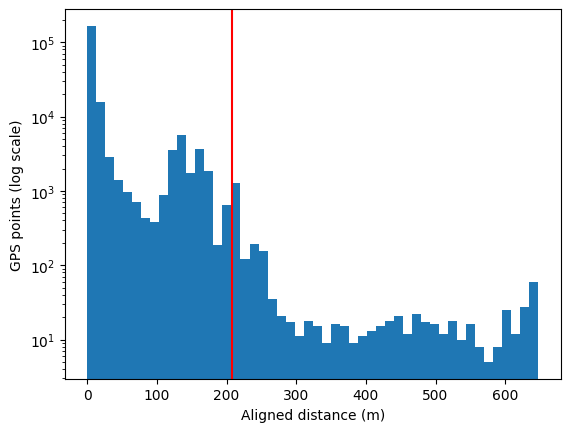

In [5]:
distances = pd.concat([labels["dist_m"] for labels in all_labels.values()], ignore_index=True)
threshold_m = np.percentile(distances, flag_percentile)
print(f"Flag threshold: {threshold_m:.2f} m | Cost cap: {cap_m} m")
display(distances.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

plt.hist(distances, bins=50, log=True)
plt.axvline(threshold_m, color="red")
plt.xlabel("Aligned distance (m)")
plt.ylabel("GPS points (log scale)")
plt.show()

## 5. Save labels and check coverage

Keep every GPS row. Flagged rows keep their aligned `route_pos` and uncapped `dist_m`, but their `true_arc_id` becomes `-1`.

Coverage counts distinct **route positions**, including separate visits to the same arc. `aligned_route_coverage` uses all points; `route_coverage` uses only unflagged points. Both are fractions from 0 to 1. Sparse GPS sampling can leave some route segments without a point.

The review table highlights trips with more than 5% flagged points or less than 80% unflagged route coverage. These are inspection cutoffs, not assertions that those trips are incorrect.

In [6]:
rows = []
for trip_id, labels in all_labels.items():
    labels["bad_gps"] = labels["dist_m"] > threshold_m
    labels.loc[labels["bad_gps"], "true_arc_id"] = -1
    labels.to_csv(label_folder / f"{trip_id}.csv", index=False)
    rows.append({
        "trip_id": trip_id,
        "gps_points": len(labels),
        "route_segments": route_sizes[trip_id],
        "flagged_points": labels["bad_gps"].sum(),
        "flagged_fraction": labels["bad_gps"].mean(),
        "aligned_route_coverage": labels["route_pos"].nunique() / route_sizes[trip_id],
        "route_coverage": labels.loc[~labels["bad_gps"], "route_pos"].nunique() / route_sizes[trip_id],
        "threshold_m": threshold_m,
        "cost_cap_m": cap_m,
    })

summary = pd.DataFrame(rows)
summary.to_csv(label_folder / "summary.csv", index=False)
print("Overall flagged fraction:", summary["flagged_points"].sum() / summary["gps_points"].sum())
display(summary.sort_values("flagged_fraction", ascending=False).head(10))
review = summary[(summary["flagged_fraction"] > 0.05) | (summary["route_coverage"] < 0.8)]
display(review.sort_values("route_coverage"))

Overall flagged fraction: 0.010003982400667891


,trip_id,gps_points,route_segments,flagged_points,flagged_fraction,aligned_route_coverage,route_coverage,threshold_m,cost_cap_m
44,00000054,19313,422,1460,0.075597,0.921801,0.921801,208.357058,150
1,00000002,7243,262,413,0.057021,0.996183,0.996183,208.357058,150
53,00000066,4325,365,183,0.042312,0.994521,0.994521,208.357058,150
35,00000043,2322,427,18,0.007752,0.939110,0.939110,208.357058,150
14,00000019,2354,545,9,0.003823,0.937615,0.937615,208.357058,150
22,00000028,3565,618,2,0.000561,0.928803,0.928803,208.357058,150
0,00000001,1315,525,0,0.000000,0.872381,0.872381,208.357058,150
58,00000072,969,131,0,0.000000,0.893130,0.893130,208.357058,150
57,00000071,850,186,0,0.000000,0.956989,0.956989,208.357058,150
56,00000070,2076,149,0,0.000000,0.919463,0.919463,208.357058,150


,trip_id,gps_points,route_segments,flagged_points,flagged_fraction,aligned_route_coverage,route_coverage,threshold_m,cost_cap_m
17,00000022,474,376,0,0.000000,0.667553,0.667553,208.357058,150
47,00000058,599,345,0,0.000000,0.704348,0.704348,208.357058,150
20,00000026,361,197,0,0.000000,0.715736,0.715736,208.357058,150
74,00000093,1211,590,0,0.000000,0.740678,0.740678,208.357058,150
48,00000060,854,520,0,0.000000,0.757692,0.757692,208.357058,150
26,00000033,5844,169,0,0.000000,0.786982,0.786982,208.357058,150
3,00000004,1064,320,0,0.000000,0.787500,0.787500,208.357058,150
43,00000053,1304,754,0,0.000000,0.789125,0.789125,208.357058,150
13,00000018,379,166,0,0.000000,0.789157,0.789157,208.357058,150
44,00000054,19313,422,1460,0.075597,0.921801,0.921801,208.357058,150


## 6. Inspect a trip on a map

Start with the trip having the highest flagged fraction. Set `trip_id` manually to inspect another one. As in notebook 01, toggle roads, the reference route, and GPS points separately.

GPS colours show route position; black points are flagged. The road layer is limited to the GPS bounding box with a small margin.

In [7]:
trip_id = summary.loc[summary["flagged_fraction"].idxmax(), "trip_id"]
labels = all_labels[trip_id]
nodes, arcs, track, route = load_trip(trip_id)
coordinates = nodes[["lat", "lon"]].to_numpy()
trip_map = folium.Map(location=[track["lat"].mean(), track["lon"].mean()], zoom_start=13)

nearby = nodes[
    nodes["lon"].between(track["lon"].min() - 0.005, track["lon"].max() + 0.005)
    & nodes["lat"].between(track["lat"].min() - 0.005, track["lat"].max() + 0.005)
].index
roads = arcs[arcs["start"].isin(nearby) & arcs["end"].isin(nearby)]
road_layer = folium.FeatureGroup(name="Roads").add_to(trip_map)
if not roads.empty:
    folium.PolyLine(coordinates[roads.to_numpy()].tolist(), color="gray", weight=1).add_to(road_layer)

route_layer = folium.FeatureGroup(name="Reference route").add_to(trip_map)
folium.PolyLine(coordinates[arcs.iloc[route["arc_id"]].to_numpy()].tolist(), color="blue", weight=4).add_to(route_layer)
gps_layer = folium.FeatureGroup(name="GPS points").add_to(trip_map)
colours = linear.viridis.scale(0, max(1, len(route) - 1))
for point in labels.itertuples(index=False):
    colour = "black" if point.bad_gps else colours(point.route_pos)
    folium.CircleMarker([point.lat, point.lon], radius=3, color=colour, fill=True,
                        fill_opacity=0.9, tooltip=f"Position {point.route_pos} | {point.dist_m:.1f} m").add_to(gps_layer)

colours.caption = "Route position (black GPS points are flagged)"
colours.add_to(trip_map)
trip_map.fit_bounds([[track["lat"].min(), track["lon"].min()], [track["lat"].max(), track["lon"].max()]])
folium.LayerControl(collapsed=False).add_to(trip_map)
Path("outputs/maps").mkdir(parents=True, exist_ok=True)
trip_map.save(f"outputs/maps/labels_{trip_id}.html")
print("Mapped trip:", trip_id)
trip_map

Mapped trip: 00000054
